# KIOS VEPL Dataset Preprocessing

This notebook preprocesses the CVAT-labeled KIOS VEPL dataset from Pascal VOC format into ML-ready tiled format.

## Key Features:
1. **Pascal VOC Format**: Loads images and segmentation masks from CVAT export
2. **Overlapping Tiles**: 25% overlap for better coverage
3. **Smart Filtering**: Removes tiles with >40% black pixels
4. **Binary Power Line Extraction**: Converts multi-class masks to binary power line masks
5. **Data Quality Control**: Statistics and visualization

## Dataset Info:
- Total images: 6,822
- Labeled images: 75 (1.1%)
- Classes: background, vegetation, power_line
- Format: Pascal VOC Segmentation

## 1. Import Required Libraries

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")
print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version: {np.__version__}")

All libraries imported successfully
OpenCV version: 4.12.0
NumPy version: 2.2.5


## 2. Configuration and Parameters

In [2]:
# =============================================================================
# DATA PATHS CONFIGURATION
# =============================================================================
BASE_DIR = '../data/kiod_vepl_labeled'
IMAGES_DIR = os.path.join(BASE_DIR, 'JPEGImages')
MASKS_DIR = os.path.join(BASE_DIR, 'SegmentationClass')
IMAGESET_FILE = os.path.join(BASE_DIR, 'ImageSets', 'Segmentation', 'default.txt')

# Output paths
PROCESSED_DIR = '../data/processed_data'
PROCESSED_IMG_DIR = os.path.join(PROCESSED_DIR, 'images')
PROCESSED_VEG_MSK_DIR = os.path.join(PROCESSED_DIR, 'veg_masks')  # NEW: Vegetation masks
PROCESSED_PL_MSK_DIR = os.path.join(PROCESSED_DIR, 'pl_masks')    # NEW: Power line masks
STATS_DIR = os.path.join(PROCESSED_DIR, 'statistics')

# =============================================================================
# TILING PARAMETERS
# =============================================================================
TILE_SIZE = 256  # Standard size for deep learning
OVERLAP_RATIO = 0.25  # 25% overlap between tiles
STRIDE = int(TILE_SIZE * (1 - OVERLAP_RATIO))  # 192 pixels stride

# =============================================================================
# CLASS VALUES (RGB) - KIOS DATASET
# =============================================================================
# Based on labelmap.txt
BACKGROUND_RGB = (0, 0, 0)        # Black
VEGETATION_RGB = (0, 255, 0)      # Green  
POWERLINE_RGB = (204, 51, 102)    # Pink/Magenta (DIFFERENT FROM ORIGINAL VEPL!)

# For binary extraction
VEGETATION_G = 255  # Green channel value for vegetation
POWERLINE_R = 204   # Red channel value for power lines

# =============================================================================
# FILTERING THRESHOLDS
# =============================================================================
MAX_BLACK_PIXEL_RATIO = 0.40  # Remove images with >40% black pixels

print("Configuration loaded successfully:")
print(f"Tile size: {TILE_SIZE}x{TILE_SIZE} pixels")
print(f"Overlap: {OVERLAP_RATIO*100}% (stride: {STRIDE} pixels)")
print(f"Class values:")
print(f"  - Background: {BACKGROUND_RGB}")
print(f"  - Vegetation: {VEGETATION_RGB}")
print(f"  - Power lines: {POWERLINE_RGB} (Pink/Magenta)")
print(f"\nOutput directories:")
print(f"  - Images: {PROCESSED_IMG_DIR}")
print(f"  - Vegetation masks: {PROCESSED_VEG_MSK_DIR}")
print(f"  - Power line masks: {PROCESSED_PL_MSK_DIR}")
print(f"Black pixel filtering: >{MAX_BLACK_PIXEL_RATIO*100}% threshold")

Configuration loaded successfully:
Tile size: 256x256 pixels
Overlap: 25.0% (stride: 192 pixels)
Class values:
  - Background: (0, 0, 0)
  - Vegetation: (0, 255, 0)
  - Power lines: (204, 51, 102) (Pink/Magenta)

Output directories:
  - Images: ../data/processed_data/images
  - Vegetation masks: ../data/processed_data/veg_masks
  - Power line masks: ../data/processed_data/pl_masks
Black pixel filtering: >40.0% threshold


## 3. Dataset Inspection

In [3]:
# Check dataset structure
print("Inspecting dataset...")
print(f"\nBase directory: {BASE_DIR}")
print(f"Images directory: {IMAGES_DIR}")
print(f"Masks directory: {MASKS_DIR}")

# Count total images and masks
all_images = [f for f in os.listdir(IMAGES_DIR) if f.endswith('.jpg')]
all_masks = [f for f in os.listdir(MASKS_DIR) if f.endswith('.png')]

print(f"\nTotal images in JPEGImages: {len(all_images)}")
print(f"Total masks in SegmentationClass: {len(all_masks)}")
print(f"Labeling progress: {len(all_masks)/len(all_images)*100:.1f}%")

# Get list of labeled image IDs
labeled_ids = set([os.path.splitext(f)[0] for f in all_masks])
print(f"\nNumber of labeled images: {len(labeled_ids)}")

# Sample a few image sizes
print("\nSample image sizes:")
for i, img_file in enumerate(all_images[:5]):
    img_path = os.path.join(IMAGES_DIR, img_file)
    img = cv2.imread(img_path)
    if img is not None:
        print(f"  {img_file}: {img.shape[1]}x{img.shape[0]} (WxH)")

Inspecting dataset...

Base directory: ../data/kiod_vepl_labeled
Images directory: ../data/kiod_vepl_labeled/JPEGImages
Masks directory: ../data/kiod_vepl_labeled/SegmentationClass

Total images in JPEGImages: 6818
Total masks in SegmentationClass: 75
Labeling progress: 1.1%

Number of labeled images: 75

Sample image sizes:
  6810_det_img_1220.jpg: 1280x720 (WxH)
  4324_X4S_t3_310820_n28.jpg: 960x960 (WxH)
  534_det_img_1050.jpg: 1280x720 (WxH)
  5400_det_img_70.jpg: 1280x720 (WxH)
  582_det_img_640.jpg: 1280x720 (WxH)


## 4. Utility Functions

In [4]:
def has_excessive_black_pixels(img_tile, threshold=0.40):
    """
    Check if an image tile has more than the specified percentage of black pixels.
    
    Args:
        img_tile: RGB image tile
        threshold: Maximum allowed black pixel ratio (0.0 to 1.0)
    
    Returns:
        bool: True if image has excessive black pixels (should be filtered out)
    """
    gray = cv2.cvtColor(img_tile, cv2.COLOR_RGB2GRAY) if len(img_tile.shape) == 3 else img_tile
    
    # Count black pixels (with small threshold for compression artifacts)
    black_pixels = np.sum(gray <= 10)
    total_pixels = gray.size
    
    black_ratio = black_pixels / total_pixels
    return black_ratio > threshold


def extract_binary_vegetation_mask(mask_rgb):
    """
    Extract binary vegetation mask from multi-class RGB mask.
    
    Args:
        mask_rgb: RGB mask with green vegetation (0, 255, 0)
    
    Returns:
        Binary mask where vegetation = 255, everything else = 0
    """
    # Check if pixel matches vegetation color (0, 255, 0)
    vegetation_mask = np.all(mask_rgb == VEGETATION_RGB, axis=2)
    
    # Convert to binary mask (0 or 255)
    binary_mask = (vegetation_mask * 255).astype(np.uint8)
    
    return binary_mask


def extract_binary_powerline_mask(mask_rgb):
    """
    Extract binary power line mask from multi-class RGB mask.
    
    Args:
        mask_rgb: RGB mask with pink power lines (204, 51, 102)
    
    Returns:
        Binary mask where power lines = 255, everything else = 0
    """
    # Check if pixel matches power line color (204, 51, 102)
    powerline_mask = np.all(mask_rgb == POWERLINE_RGB, axis=2)
    
    # Convert to binary mask (0 or 255)
    binary_mask = (powerline_mask * 255).astype(np.uint8)
    
    return binary_mask


def analyze_mask_tile(mask_rgb, veg_binary_mask, pl_binary_mask):
    """
    Analyze a mask tile to extract class statistics.
    
    Returns:
        (background_pixels, vegetation_pixels, powerline_pixels)
    """
    total_pixels = mask_rgb.shape[0] * mask_rgb.shape[1]
    
    # Count pixels for each class
    vegetation_pixels = np.sum(veg_binary_mask == 255)
    powerline_pixels = np.sum(pl_binary_mask == 255)
    
    # Background is everything else
    background_pixels = total_pixels - vegetation_pixels - powerline_pixels
    
    return background_pixels, vegetation_pixels, powerline_pixels


def validate_tile_pair(img_tile, mask_tile):
    """
    Validate that image and mask tiles are properly formatted and pass quality checks.
    
    Returns:
        (is_valid, reason)
    """
    # Check dimensions
    if img_tile.shape[:2] != (TILE_SIZE, TILE_SIZE):
        return False, f"Image tile wrong size: {img_tile.shape}"
    
    if mask_tile.shape[:2] != (TILE_SIZE, TILE_SIZE):
        return False, f"Mask tile wrong size: {mask_tile.shape}"
    
    # Check image is not corrupted
    if np.all(img_tile == img_tile[0, 0]) or np.all(img_tile == 0):
        return False, "Image tile appears corrupted"
    
    # Check for excessive black pixels
    if has_excessive_black_pixels(img_tile, MAX_BLACK_PIXEL_RATIO):
        return False, f"Image has >{MAX_BLACK_PIXEL_RATIO*100}% black pixels"
    
    return True, "Valid"


def save_statistics(stats, output_path):
    """
    Save processing statistics to JSON file.
    """
    def convert_numpy_types(obj):
        if isinstance(obj, dict):
            return {key: convert_numpy_types(value) for key, value in obj.items()}
        elif isinstance(obj, list):
            return [convert_numpy_types(item) for item in obj]
        elif isinstance(obj, (np.integer, np.int64, np.int32)):
            return int(obj)
        elif isinstance(obj, (np.floating, np.float64, np.float32)):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        else:
            return obj
    
    serializable_stats = convert_numpy_types(stats)
    
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with open(output_path, 'w') as f:
        json.dump(serializable_stats, f, indent=2)


def visualize_samples(img_dir, veg_mask_dir, pl_mask_dir, num_samples=4):
    """
    Visualize random samples from processed tiles with both mask types.
    """
    if not os.path.exists(img_dir) or not os.path.exists(veg_mask_dir):
        print(f"Directories don't exist yet")
        return
    
    img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.png')])
    
    if len(img_files) == 0:
        print("No PNG files found. Run preprocessing first.")
        return
    
    if len(img_files) < num_samples:
        num_samples = len(img_files)
    
    # Select random samples
    indices = np.random.choice(len(img_files), num_samples, replace=False)
    
    fig, axes = plt.subplots(3, num_samples, figsize=(4*num_samples, 12))
    if num_samples == 1:
        axes = axes.reshape(3, 1)
    
    for i, idx in enumerate(indices):
        # Load image and masks
        img_path = os.path.join(img_dir, img_files[idx])
        veg_mask_path = os.path.join(veg_mask_dir, img_files[idx])
        pl_mask_path = os.path.join(pl_mask_dir, img_files[idx])
        
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        veg_mask = cv2.imread(veg_mask_path, cv2.IMREAD_GRAYSCALE)
        pl_mask = cv2.imread(pl_mask_path, cv2.IMREAD_GRAYSCALE)
        
        # Display
        axes[0, i].imshow(img)
        axes[0, i].set_title(f'Image {i+1}', fontsize=10)
        axes[0, i].axis('off')
        
        axes[1, i].imshow(veg_mask, cmap='Greens', vmin=0, vmax=255)
        axes[1, i].set_title(f'Vegetation Mask', fontsize=10)
        axes[1, i].axis('off')
        
        axes[2, i].imshow(pl_mask, cmap='Reds', vmin=0, vmax=255)
        axes[2, i].set_title(f'Power Line Mask', fontsize=10)
        axes[2, i].axis('off')
    
    plt.tight_layout()
    plt.suptitle('Sample Tiles with Both Mask Types', fontsize=14, y=1.01)
    plt.show()

print("Utility functions defined successfully")

Utility functions defined successfully


## 5. Main Processing Function

In [5]:
def process_kios_dataset():
    """
    Process KIOS VEPL Pascal VOC dataset into tiled format for deep learning.
    Creates separate vegetation and power line binary masks.
    Only processes images that have corresponding segmentation masks.
    """
    print("Starting KIOS VEPL dataset preprocessing...")
    print("Creating BOTH vegetation and power line masks...")
    
    # Create output directories
    for dir_path in [PROCESSED_IMG_DIR, PROCESSED_VEG_MSK_DIR, PROCESSED_PL_MSK_DIR, STATS_DIR]:
        os.makedirs(dir_path, exist_ok=True)
        print(f"Created directory: {dir_path}")
    
    # Get list of labeled images (images that have corresponding masks)
    mask_files = sorted([f for f in os.listdir(MASKS_DIR) if f.endswith('.png')])
    labeled_ids = [os.path.splitext(f)[0] for f in mask_files]
    
    print(f"\nFound {len(labeled_ids)} labeled images to process")
    
    # Initialize statistics
    stats = {
        'total_source_images': len(labeled_ids),
        'total_tiles_processed': 0,
        'total_tiles_generated': 0,
        'tiles_filtered_black_pixels': 0,
        'tiles_corrupted': 0,
        'class_distribution': {
            'background_pixels': 0,
            'vegetation_pixels': 0,
            'powerline_pixels': 0
        },
        'source_images': labeled_ids,
        'config': {
            'tile_size': TILE_SIZE,
            'stride': STRIDE,
            'overlap_ratio': OVERLAP_RATIO,
            'max_black_pixel_ratio': MAX_BLACK_PIXEL_RATIO,
            'vegetation_rgb': VEGETATION_RGB,
            'powerline_rgb': POWERLINE_RGB
        }
    }
    
    tile_counter = 0
    
    # Process each labeled image
    for img_id in tqdm(labeled_ids, desc="Processing images"):
        # Load image and mask
        img_path = os.path.join(IMAGES_DIR, f"{img_id}.jpg")
        mask_path = os.path.join(MASKS_DIR, f"{img_id}.png")
        
        if not os.path.exists(img_path):
            print(f"Warning: Image not found: {img_path}")
            continue
        
        # Read image and mask
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        mask = cv2.imread(mask_path)
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
        
        height, width = img.shape[:2]
        
        # Calculate number of tiles for this image
        n_cols = max(1, (width - TILE_SIZE) // STRIDE + 1)
        n_rows = max(1, (height - TILE_SIZE) // STRIDE + 1)
        
        # Generate overlapping tiles
        for col in range(0, width - TILE_SIZE + 1, STRIDE):
            for row in range(0, height - TILE_SIZE + 1, STRIDE):
                stats['total_tiles_processed'] += 1
                
                # Extract tiles
                img_tile = img[row:row+TILE_SIZE, col:col+TILE_SIZE]
                mask_tile = mask[row:row+TILE_SIZE, col:col+TILE_SIZE]
                
                # Validate tile dimensions and quality
                is_valid, reason = validate_tile_pair(img_tile, mask_tile)
                if not is_valid:
                    if "black pixels" in reason:
                        stats['tiles_filtered_black_pixels'] += 1
                    else:
                        stats['tiles_corrupted'] += 1
                    continue
                
                # Extract BOTH binary masks
                veg_binary_mask = extract_binary_vegetation_mask(mask_tile)
                pl_binary_mask = extract_binary_powerline_mask(mask_tile)
                
                # Analyze mask content
                bg_pixels, veg_pixels, pl_pixels = analyze_mask_tile(mask_tile, veg_binary_mask, pl_binary_mask)
                
                # Update class statistics
                stats['class_distribution']['background_pixels'] += bg_pixels
                stats['class_distribution']['vegetation_pixels'] += veg_pixels
                stats['class_distribution']['powerline_pixels'] += pl_pixels
                
                # Save the valid tiles
                try:
                    # Convert RGB to BGR for OpenCV
                    img_tile_bgr = cv2.cvtColor(img_tile, cv2.COLOR_RGB2BGR)
                    
                    # Save with meaningful names
                    base_name = f"tile_{tile_counter:06d}"
                    img_save_path = os.path.join(PROCESSED_IMG_DIR, f'{base_name}.png')
                    veg_mask_save_path = os.path.join(PROCESSED_VEG_MSK_DIR, f'{base_name}.png')
                    pl_mask_save_path = os.path.join(PROCESSED_PL_MSK_DIR, f'{base_name}.png')
                    
                    cv2.imwrite(img_save_path, img_tile_bgr)
                    cv2.imwrite(veg_mask_save_path, veg_binary_mask)  # Vegetation mask
                    cv2.imwrite(pl_mask_save_path, pl_binary_mask)     # Power line mask
                    
                    tile_counter += 1
                    stats['total_tiles_generated'] += 1
                    
                except Exception as e:
                    print(f"Error saving tile {tile_counter}: {e}")
                    stats['tiles_corrupted'] += 1
    
    # Finalize statistics
    total_pixels = stats['class_distribution']['background_pixels'] + \
                   stats['class_distribution']['vegetation_pixels'] + \
                   stats['class_distribution']['powerline_pixels']
    
    if total_pixels > 0:
        stats['class_percentages'] = {
            'background': stats['class_distribution']['background_pixels'] / total_pixels * 100,
            'vegetation': stats['class_distribution']['vegetation_pixels'] / total_pixels * 100,
            'powerlines': stats['class_distribution']['powerline_pixels'] / total_pixels * 100
        }
    
    # Save statistics
    stats_file = os.path.join(STATS_DIR, 'preprocessing_statistics.json')
    save_statistics(stats, stats_file)
    
    # Print summary
    print("\n" + "="*70)
    print("PREPROCESSING COMPLETED SUCCESSFULLY")
    print("="*70)
    print(f"Source images processed: {stats['total_source_images']}")
    print(f"Total tiles processed: {stats['total_tiles_processed']:,}")
    print(f"Valid tiles generated: {stats['total_tiles_generated']:,}")
    print(f"Tiles filtered (black pixels): {stats['tiles_filtered_black_pixels']:,}")
    print(f"Corrupted tiles: {stats['tiles_corrupted']:,}")
    
    if stats['total_tiles_processed'] > 0:
        success_rate = stats['total_tiles_generated'] / stats['total_tiles_processed'] * 100
        print(f"Success rate: {success_rate:.1f}%")
    
    if 'class_percentages' in stats:
        print("\nCLASS DISTRIBUTION:")
        print(f"   Background: {stats['class_percentages']['background']:.1f}%")
        print(f"   Vegetation: {stats['class_percentages']['vegetation']:.1f}%")
        print(f"   Power lines: {stats['class_percentages']['powerlines']:.1f}%")
    
    print(f"\nSTATISTICS:")
    print(f"   Saved to: {stats_file}")
    print(f"\nOUTPUT DIRECTORIES:")
    print(f"   Images: {PROCESSED_IMG_DIR}")
    print(f"   Vegetation masks: {PROCESSED_VEG_MSK_DIR}")
    print(f"   Power line masks: {PROCESSED_PL_MSK_DIR}")
    
    return stats

print("Main processing function defined successfully")

Main processing function defined successfully


## 6. Execute Processing

In [6]:
# Run the preprocessing
preprocessing_stats = process_kios_dataset()

Starting KIOS VEPL dataset preprocessing...
Creating BOTH vegetation and power line masks...
Created directory: ../data/processed_data/images
Created directory: ../data/processed_data/veg_masks
Created directory: ../data/processed_data/pl_masks
Created directory: ../data/processed_data/statistics

Found 75 labeled images to process


Processing images: 100%|██████████| 75/75 [00:13<00:00,  5.46it/s]


PREPROCESSING COMPLETED SUCCESSFULLY
Source images processed: 75
Total tiles processed: 2,139
Valid tiles generated: 2,139
Tiles filtered (black pixels): 0
Corrupted tiles: 0
Success rate: 100.0%

CLASS DISTRIBUTION:
   Background: 90.0%
   Vegetation: 8.5%
   Power lines: 1.5%

STATISTICS:
   Saved to: ../data/processed_data/statistics/preprocessing_statistics.json

OUTPUT DIRECTORIES:
   Images: ../data/processed_data/images
   Vegetation masks: ../data/processed_data/veg_masks
   Power line masks: ../data/processed_data/pl_masks


## 7. Visualization and Quality Analysis

Visualizing random sample tiles...


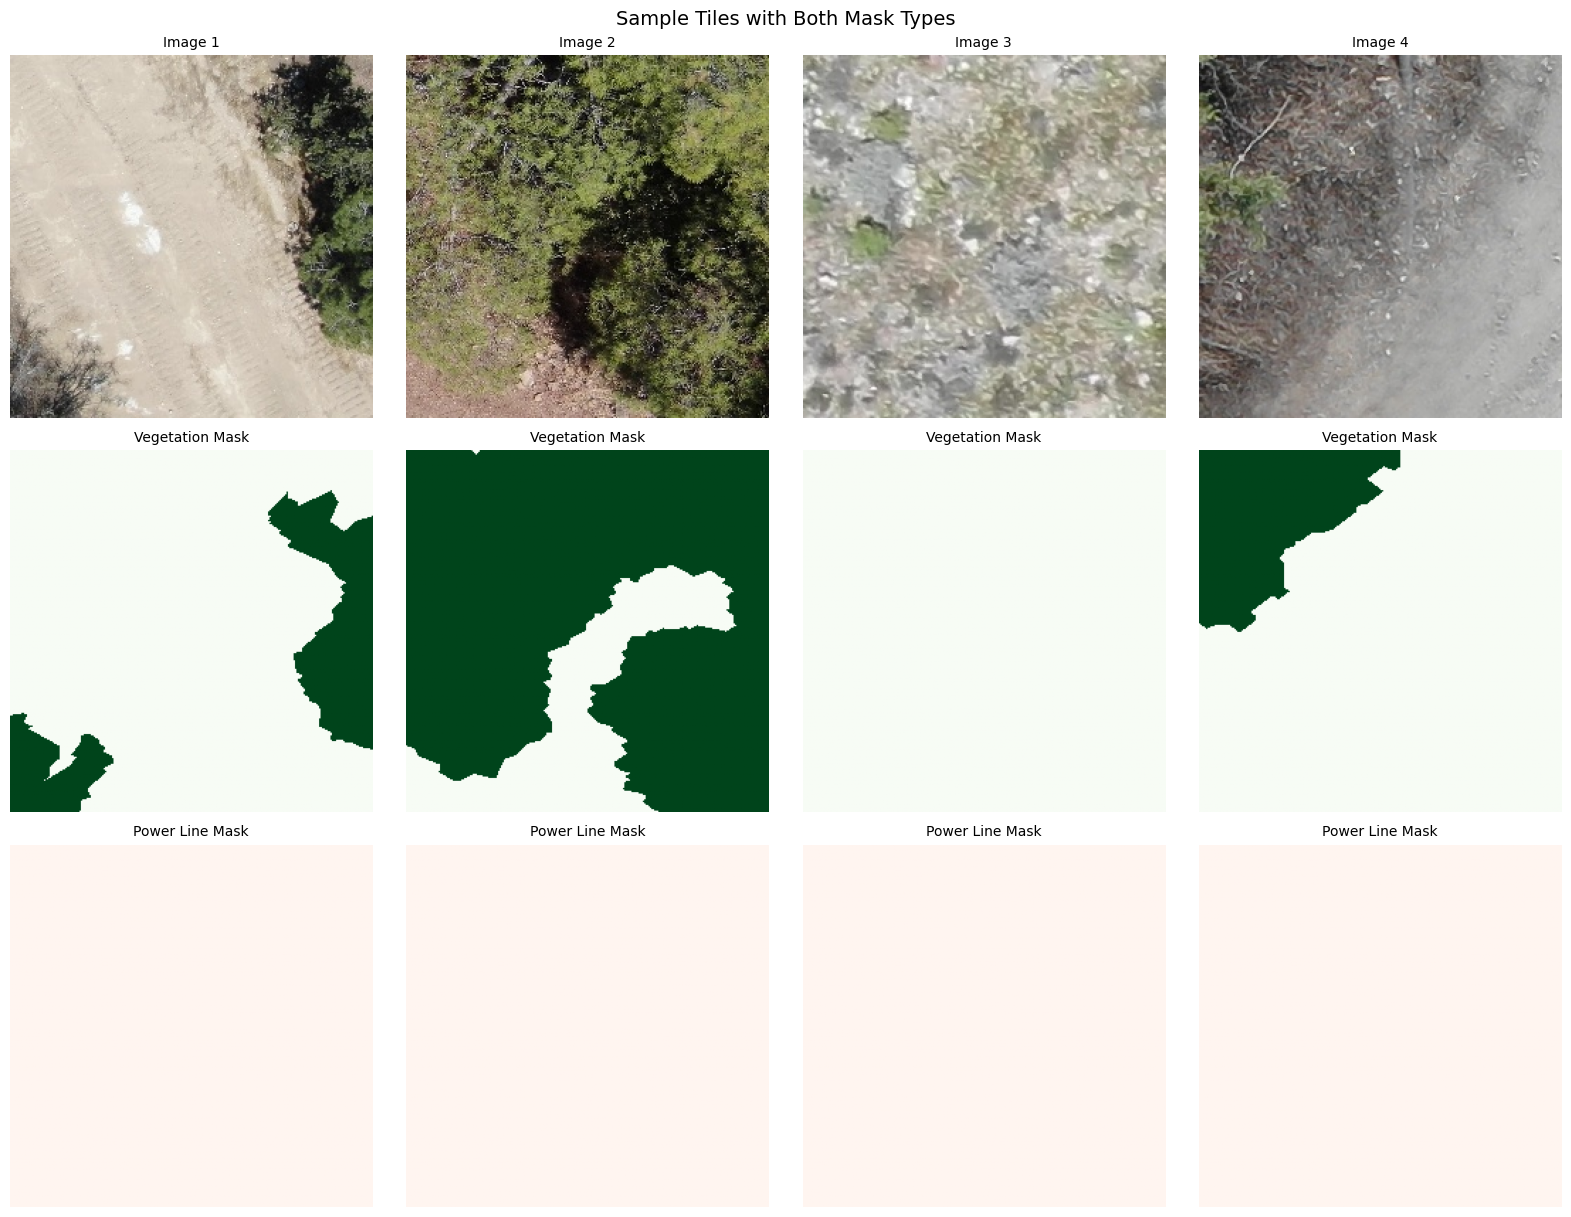

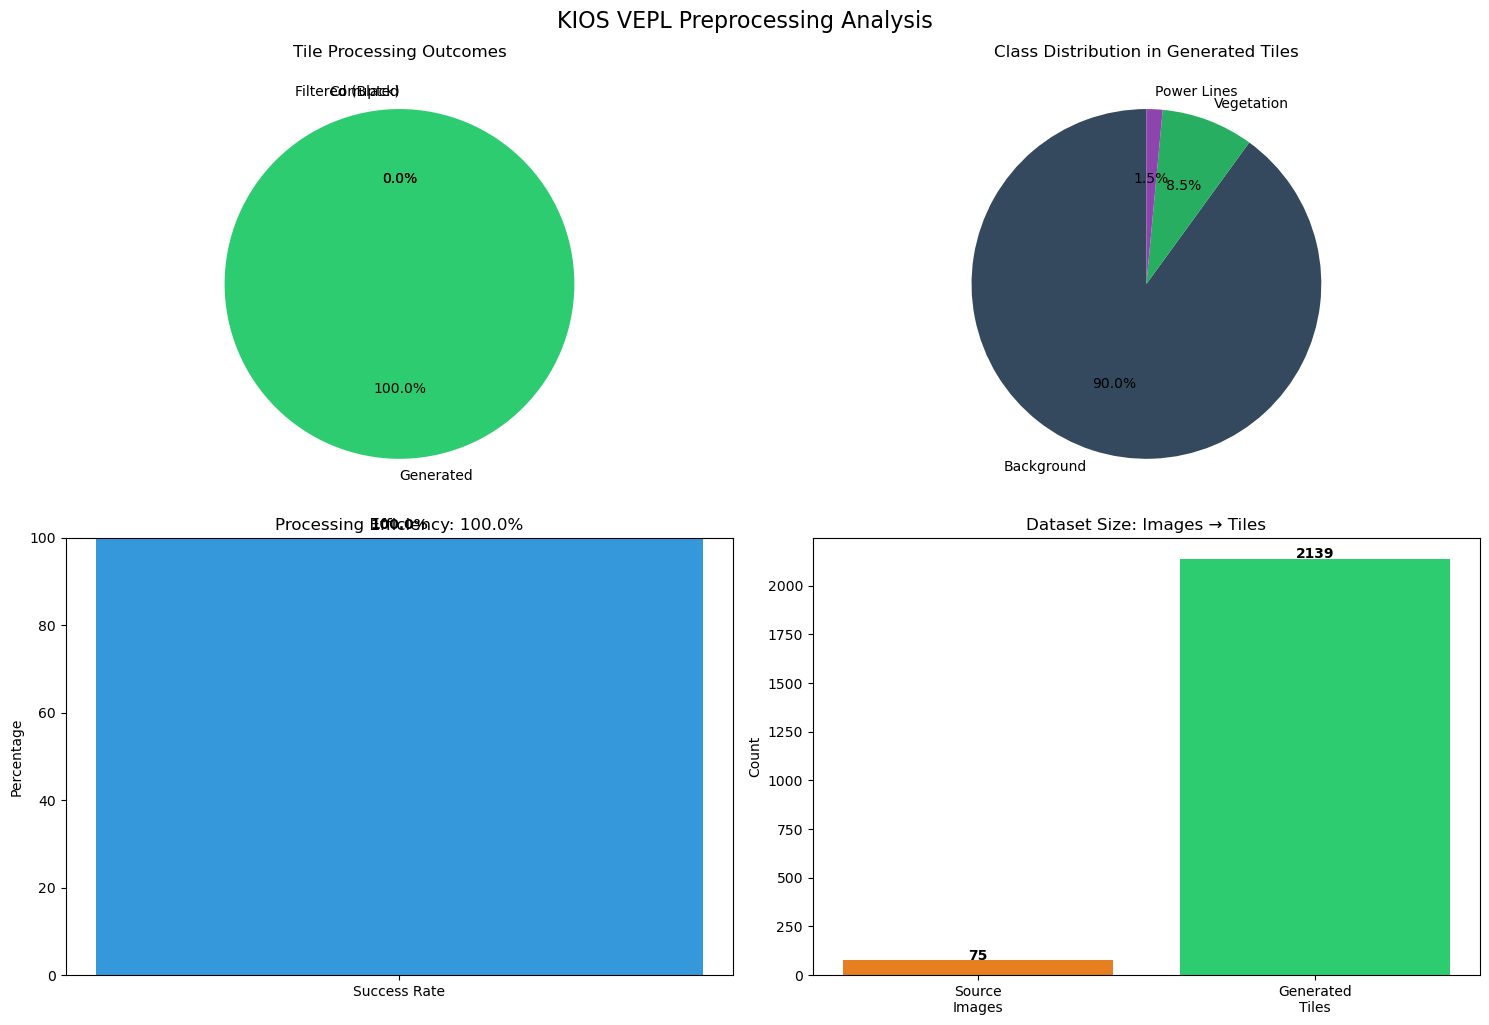


Preprocessing and quality analysis completed!

✅ Created 2,139 tiles
✅ Vegetation masks: ../data/processed_data/veg_masks
✅ Power line masks: ../data/processed_data/pl_masks


In [7]:
# Visualize sample tiles with BOTH mask types
print("Visualizing random sample tiles...")
visualize_samples(PROCESSED_IMG_DIR, PROCESSED_VEG_MSK_DIR, PROCESSED_PL_MSK_DIR, num_samples=4)

# Create processing summary visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# Processing outcome pie chart
outcomes = ['Generated', 'Filtered (Black)', 'Corrupted']
values = [
    preprocessing_stats['total_tiles_generated'],
    preprocessing_stats['tiles_filtered_black_pixels'],
    preprocessing_stats['tiles_corrupted']
]
colors = ['#2ecc71', '#e74c3c', '#95a5a6']
ax1.pie(values, labels=outcomes, colors=colors, autopct='%1.1f%%', startangle=90)
ax1.set_title('Tile Processing Outcomes')

# Class distribution pie chart
if 'class_percentages' in preprocessing_stats:
    classes = ['Background', 'Vegetation', 'Power Lines']
    percentages = [
        preprocessing_stats['class_percentages']['background'],
        preprocessing_stats['class_percentages']['vegetation'],
        preprocessing_stats['class_percentages']['powerlines']
    ]
    class_colors = ['#34495e', '#27ae60', '#8e44ad']
    ax2.pie(percentages, labels=classes, colors=class_colors, autopct='%1.1f%%', startangle=90)
    ax2.set_title('Class Distribution in Generated Tiles')

# Processing efficiency bar chart
if preprocessing_stats['total_tiles_processed'] > 0:
    success_rate = preprocessing_stats['total_tiles_generated'] / preprocessing_stats['total_tiles_processed'] * 100
    ax3.bar(['Success Rate'], [success_rate], color='#3498db', width=0.5)
    ax3.set_ylim(0, 100)
    ax3.set_ylabel('Percentage')
    ax3.set_title(f'Processing Efficiency: {success_rate:.1f}%')
    ax3.text(0, success_rate + 2, f'{success_rate:.1f}%', ha='center', fontweight='bold')

# Dataset size comparison
ax4.bar(
    ['Source\nImages', 'Generated\nTiles'],
    [preprocessing_stats['total_source_images'], preprocessing_stats['total_tiles_generated']],
    color=['#e67e22', '#2ecc71']
)
ax4.set_ylabel('Count')
ax4.set_title('Dataset Size: Images → Tiles')
ax4.text(0, preprocessing_stats['total_source_images'] + 5, 
         str(preprocessing_stats['total_source_images']), ha='center', fontweight='bold')
ax4.text(1, preprocessing_stats['total_tiles_generated'] + 5,
         str(preprocessing_stats['total_tiles_generated']), ha='center', fontweight='bold')

plt.tight_layout()
plt.suptitle('KIOS VEPL Preprocessing Analysis', fontsize=16, y=1.02)
plt.show()

print("\nPreprocessing and quality analysis completed!")
print(f"\n✅ Created {preprocessing_stats['total_tiles_generated']:,} tiles")
print(f"✅ Vegetation masks: {PROCESSED_VEG_MSK_DIR}")
print(f"✅ Power line masks: {PROCESSED_PL_MSK_DIR}")

## 8. Data Validation for Deep Learning

In [8]:
# Validate that the processed data is ready for deep learning
print("Validating processed data for deep learning...")

# Check if we have sufficient data
img_files = [f for f in os.listdir(PROCESSED_IMG_DIR) if f.endswith('.png')]
veg_mask_files = [f for f in os.listdir(PROCESSED_VEG_MSK_DIR) if f.endswith('.png')]
pl_mask_files = [f for f in os.listdir(PROCESSED_PL_MSK_DIR) if f.endswith('.png')]

print(f"Image tiles: {len(img_files)}")
print(f"Vegetation mask tiles: {len(veg_mask_files)}")
print(f"Power line mask tiles: {len(pl_mask_files)}")

if len(img_files) != len(veg_mask_files) or len(img_files) != len(pl_mask_files):
    print("⚠️  ERROR: Mismatch between image and mask counts!")
else:
    print("✅ Image and mask counts match")

# Verify binary masks
print("\nVerifying binary mask format...")
sample_veg_mask = cv2.imread(os.path.join(PROCESSED_VEG_MSK_DIR, veg_mask_files[0]), cv2.IMREAD_GRAYSCALE)
sample_pl_mask = cv2.imread(os.path.join(PROCESSED_PL_MSK_DIR, pl_mask_files[0]), cv2.IMREAD_GRAYSCALE)

veg_unique = np.unique(sample_veg_mask)
pl_unique = np.unique(sample_pl_mask)

print(f"Vegetation mask unique values: {veg_unique}")
print(f"Power line mask unique values: {pl_unique}")

if len(veg_unique) <= 2 and 0 in veg_unique and len(pl_unique) <= 2 and 0 in pl_unique:
    print("✅ Both mask types are correctly formatted as binary (0 and 255)")
else:
    print("⚠️  Warning: Masks may not be binary format")

# Recommendations for training
total_tiles = len(img_files)
print(f"\n{'='*70}")
print("DEEP LEARNING RECOMMENDATIONS")
print(f"{'='*70}")

if total_tiles < 100:
    print(f"⚠️  Dataset is VERY small ({total_tiles} tiles).")
    print("   Recommendations:")
    print("   - Label more images to get at least 500 tiles")
    print("   - Use AGGRESSIVE data augmentation")
    print("   - Use very small batch sizes (4-8)")
    print("   - Train for more epochs (15-20)")
    print("   - Monitor for overfitting carefully")
elif total_tiles < 500:
    print(f"✅ Moderate dataset size ({total_tiles} tiles).")
    print("   Recommendations:")
    print("   - Use aggressive data augmentation")
    print("   - Batch sizes of 8-16")
    print("   - Train for 15-20 epochs")
    print("   - Use early stopping (patience=5)")
else:
    print(f"✅ Good dataset size ({total_tiles} tiles).")
    print("   Recommendations:")
    print("   - Standard data augmentation")
    print("   - Batch sizes of 16-32")
    print("   - Standard training procedures")

# Data split recommendations
train_size = int(0.6 * total_tiles)
val_size = int(0.2 * total_tiles)
test_size = total_tiles - train_size - val_size

print(f"\nRECOMMENDED DATA SPLIT:")
print(f"   Training: {train_size} tiles (60%)")
print(f"   Validation: {val_size} tiles (20%)")
print(f"   Testing: {test_size} tiles (20%)")

print(f"\n{'='*70}")
print("✅ Data preprocessing completed successfully!")
print(f"{'='*70}")
print(f"\nYou now have TWO separate datasets:")
print(f"\n1️⃣  VEGETATION SEGMENTATION:")
print(f"   - Images: {PROCESSED_IMG_DIR}")
print(f"   - Masks: {PROCESSED_VEG_MSK_DIR}")
print(f"   - Training notebook: train_kios_vepl_veg.ipynb")
print(f"   - Model: U-Net + VGG16")
print(f"   - Loss: BCEWithLogitsLoss")
print(f"\n2️⃣  POWER LINE DETECTION:")
print(f"   - Images: {PROCESSED_IMG_DIR}")
print(f"   - Masks: {PROCESSED_PL_MSK_DIR}")
print(f"   - Training notebook: train_kios_vepl_pl.ipynb")
print(f"   - Model: DeepLabV3 + ResNet34")
print(f"   - Loss: Combined Tversky + BCE")
print(f"\nBoth models use the SAME images but DIFFERENT masks!")

Validating processed data for deep learning...
Image tiles: 2139
Vegetation mask tiles: 2139
Power line mask tiles: 2139
✅ Image and mask counts match

Verifying binary mask format...
Vegetation mask unique values: [0]
Power line mask unique values: [0]
✅ Both mask types are correctly formatted as binary (0 and 255)

DEEP LEARNING RECOMMENDATIONS
✅ Good dataset size (2139 tiles).
   Recommendations:
   - Standard data augmentation
   - Batch sizes of 16-32
   - Standard training procedures

RECOMMENDED DATA SPLIT:
   Training: 1283 tiles (60%)
   Validation: 427 tiles (20%)
   Testing: 429 tiles (20%)

✅ Data preprocessing completed successfully!

You now have TWO separate datasets:

1️⃣  VEGETATION SEGMENTATION:
   - Images: ../data/processed_data/images
   - Masks: ../data/processed_data/veg_masks
   - Training notebook: train_kios_vepl_veg.ipynb
   - Model: U-Net + VGG16
   - Loss: BCEWithLogitsLoss

2️⃣  POWER LINE DETECTION:
   - Images: ../data/processed_data/images
   - Masks: .